# Lab 7: Normal Distributions and Variability of Sample Means

In today's lab, we will learn about [the variability of sample means](https://inferentialthinking.com/chapters/14/5/Variability_of_the_Sample_Mean.html) as well as [the normal distribution](https://www.inferentialthinking.com/chapters/14/3/SD_and_the_Normal_Curve.html).

In [5]:
# Run this cell, but please don't change it. 
import numpy as np
from datascience import *

import matplotlib.pyplot as plots
plots.style.use('fivethirtyeight')
%matplotlib inline

# 1. Normal Distribution

When we visualize the distribution of a sample, we are often interested in the mean and the standard deviation of the sample (for the rest of this lab, we will abbreviate “standard deviation” as “SD”). These two summary statistics can give us a bird’s-eye view of a distribution by telling us where it is centered on the number line and how spread out it is, respectively

**Question 1.1.** The next cell loads the table `births` from lecture, which is a large random sample of US births and includes information about mother-child pairs. 

Plot the distribution of mothers’ ages from the table. Don’t change the last line, which will plot the mean of the sample on the distribution itself.

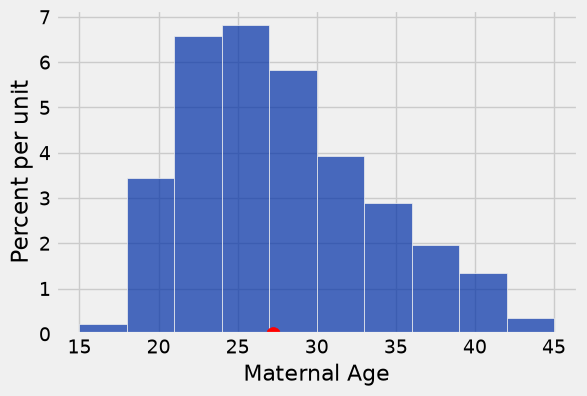

In [6]:
births = Table.read_table('../../shared/Data/baby.csv')

births.hist("Maternal Age")

# Do not change this line
plots.scatter(np.mean(births.column("Maternal Age")), 0, color='red', s=100, zorder=2)

From the plot above, we can see that the mean is the center of gravity or balance point of the distribution. If you cut the distribution out of cardboard, and then placed your finger at the mean, the distribution would perfectly balance on your finger. Since the distribution above is right-skewed, meaning that it has a long right tail, the mean is typically larger than the median because the tail pulls the mean to the right. Conversely, for a left-skewed distribution, the mean is typically smaller than the median.

Run the following cell to compare the mean (red) and median (green) of the distribution of mothers' ages.

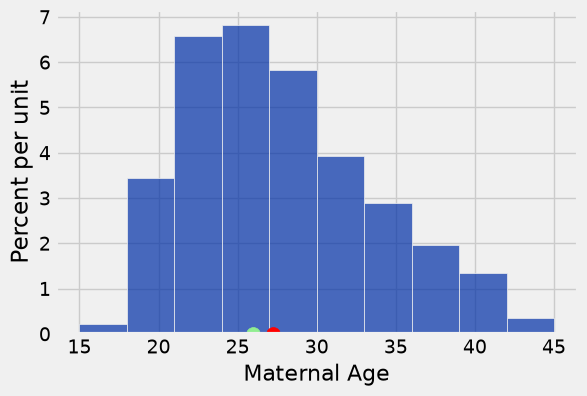

In [7]:
births.hist("Maternal Age")
plots.scatter(np.mean(births.column("Maternal Age")), 0, color='red', s=100, zorder=2)
plots.scatter(np.median(births.column("Maternal Age")), 0, color='lightgreen', s=100, zorder=2)

We are also interested in the standard deviation of mother’s ages. The SD gives us a sense of how variable mothers’ ages are around the mean age. If the SD is large, mothers’ ages will tend to be spread over a larger range around the mean. If the SD is small, mothers’ ages will tend to be more tightly clustered around the mean age.

**The SD of an array is the root mean square of the deviations from the mean.**

Fun fact! σ (Greek letter sigma) is used to represent the SD and  μ (Greek letter mu) is used for the mean.

**Question 1.2.** Fill in the code below to determine the mean and standard deviation for maternal age. Numpy has a function for the standard deviation: `np.std()`. Run the cell to see the width of one SD (yellow) from the sample mean (red) plotted on the histogram of maternal ages.

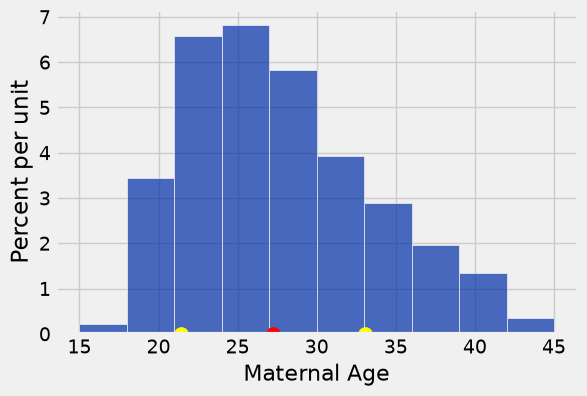

In [8]:
age_mean = np.mean(births.column("Maternal Age"))
age_sd = np.std(births.column("Maternal Age"))
births.hist("Maternal Age")

plots.scatter(age_mean, 0, color='red', s=100, zorder=2)
plots.scatter(age_mean+age_sd, 0, color='yellow', s=100, zorder=2)
plots.scatter(age_mean-age_sd, 0, color='yellow', s=100, zorder=2)

In this histogram, the standard deviation is not easy to identify just by looking at the graph.

However, for some approximately normal distributions, the standard deviation is easier to identify visually.For example, in an approximately normal distribution, one standard deviation from the mean corresponds approximately to the curve’s points of inflection (the point where the curve begins to change the direction of its curvature). 

**Question 1.3.** Fill in the following code to examine the distribution of maternal heights, which is approximately normally distributed. We’ll plot the standard deviation on the histogram, as before - notice where one standard deviation (yellow) away from the mean (red) falls on the plot.

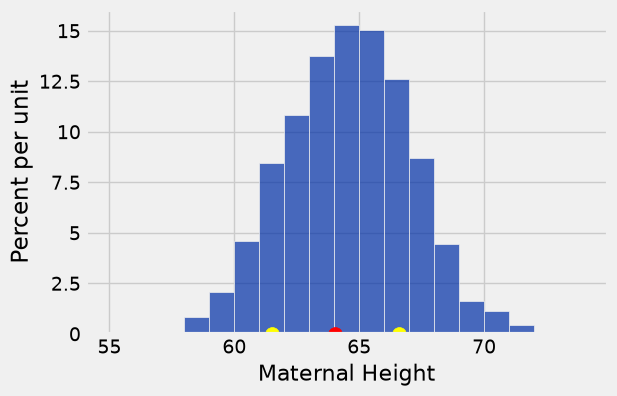

In [9]:
height_mean = np.mean(births.column("Maternal Height"))
height_sd = np.std(births.column("Maternal Height"))
births.hist("Maternal Height", bins=np.arange(55,75,1))

plots.scatter(height_mean, 0, color='red', s=100, zorder=2)
plots.scatter(height_mean+height_sd, 0, color='yellow', s=100, zorder=2)
plots.scatter(height_mean-height_sd, 0, color='yellow', s=100, zorder=2)

We do not always know how a variable will be distributed, so we should be cautious about assuming that the population itself is normally distributed. However, under appropriate conditions, the Central Limit Theorem says that the sampling distribution of the sum or mean of a sufficiently large random sample is approximately normal, regardless of the shape of the original population distribution.

The Central Limit Theorem applies to the distribution of a statistic calculated from repeated samples. It does not say that the original population, or a single sample from that population, will be normally distributed.

The next section will explore distributions of sample means, and you will see how the standard deviation of these distributions depends on sample sizes.

# 2. Variability of the Sample Mean

Under the conditions of the Central Limit Theorem, the sampling distribution of the mean of a sufficiently large random sample is approximately normal. The sampling distribution of the sample mean is centered at the population mean. Some of the sample means are higher and some are lower, but the deviations from the population mean are roughly symmetric on either side, as we have seen repeatedly. Formally, the sample mean is an unbiased estimator of the population mean.

In our simulations, we also noticed that the means of larger samples tend to be more tightly clustered around the population mean than means of smaller samples. In this section, we will quantify the [variability of the sample mean](https://www.inferentialthinking.com/chapters/14/5/Variability_of_the_Sample_Mean.html) and develop a relation between the variability and the sample size.

Let's take a look at the salaries of permanent employees of UNC Chapel Hill as of September 30th, 2026. 

*Note: If you get stuck on any part of this lab, please refer to [chapter 14 of the textbook](https://www.inferentialthinking.com/chapters/14/Why_the_Mean_Matters.html).*

In [10]:
salaries = Table.read_table('../../shared/Data/UNC_CH_Salaries26.csv')
salaries

BASE_SALARY
100749
204000
72429
149350
162200
89610
96820
64591
289201
134396


In [11]:
salary_mean = np.mean(salaries.column('BASE_SALARY'))
salary_median = np.median(salaries.column('BASE_SALARY'))
print('Mean salary of UNC-CH employees in September 2026 is: ', round(salary_mean, 2))
print('Median salary of UNC-CH employees in September 2026 is: ', round(salary_median, 2))

Mean salary of UNC-CH employees in September 2026 is:  119746.12
Median salary of UNC-CH employees in September 2026 is:  87550.0


Text(0.5, 1.0, 'Sept 2026 salaries of UNC-CH employees')

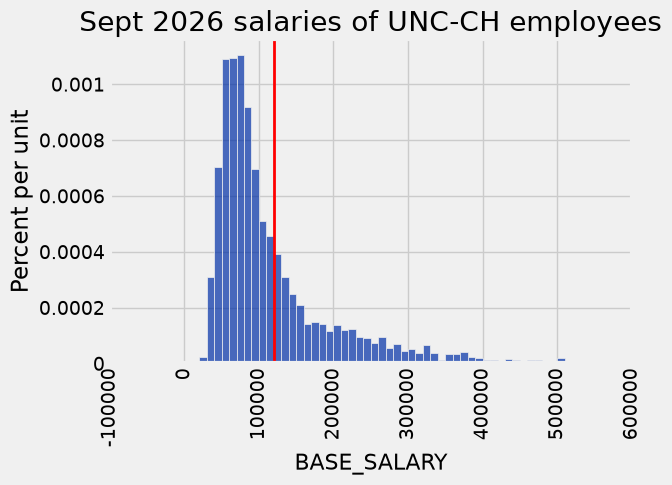

In [12]:
salaries.hist('BASE_SALARY', bins=np.arange(0, 500000+10001, 10000))
plots.axvline(salary_mean, color='red', lw=2)
plots.title('Sept 2026 salaries of UNC-CH employees')

Clearly, the population does not follow a normal distribution. Keep that in mind as we progress through these exercises.

Let's take random samples *with replacement* and look at the probability distribution of the sample mean. As usual, we will use simulation to get an empirical approximation to this distribution.

**Question 2.1.** Define a function `one_sample_mean`. Its arguments should be `table` (the table to sample from), `label` (the label of the column containing the variable), and `sample size` (the number of observations in the sample). It should sample with replacement from the table and return the mean of the `label` column of the sample.

In [13]:
def one_sample_mean(table, label, sample_size):
    new_sample = table.sample(sample_size, with_replacement=True)
    new_sample_mean = np.mean(new_sample.column(label))
    return new_sample_mean

**Question 2.2.** Use `one_sample_mean` to define a function called `simulate_sample_mean`. The arguments are the table to sample from, the label of the column containing the variable, the sample size, and the number of simulations.

For each repetition, the function should draw a new sample with replacement, calculate its mean using one_sample_mean, and append that mean to the array means. Complete the two lines containing ellipses. The completed function should store all simulated sample means in means. The remaining code displays the empirical histogram and prints relevant quantities.

In [14]:
"""Empirical distribution of random sample means"""

def simulate_sample_mean(table, label, sample_size, repetitions):
    
    means = make_array()

    for i in np.arange(repetitions):
        new_sample_mean = one_sample_mean(table, label, sample_size)
        means = np.append(means, new_sample_mean)

    sample_means = Table().with_column('Sample Means', means)
    
    # Display empirical histogram and print all relevant quantities – don't change this!
    sample_means.hist(bins=30)
    plots.xlabel('Sample Means')
    plots.title('Sample Size ' + str(sample_size))
    print("Sample size: ", sample_size)
    print("Population mean:", np.mean(table.column(label)))
    print("Average of sample means: ", np.mean(means))
    print("Population SD:", np.std(table.column(label)))
    print("SD of sample means:", np.std(means))
    return np.std(means)

The remaining exercises depend on this function, so test it carefully before continuing.

 In the following cell, we will create a sample of size 100 from `salaries` and graph it using our new `simulate_sample_mean` function.
 
 *Hint: You should see an approximately bell-shaped distribution of sample means. If not, check your function.*

Sample size:  100
Population mean: 119746.117558
Average of sample means:  119828.218472
Population SD: 110592.449798
SD of sample means: 11104.4355818


11104.435581755588

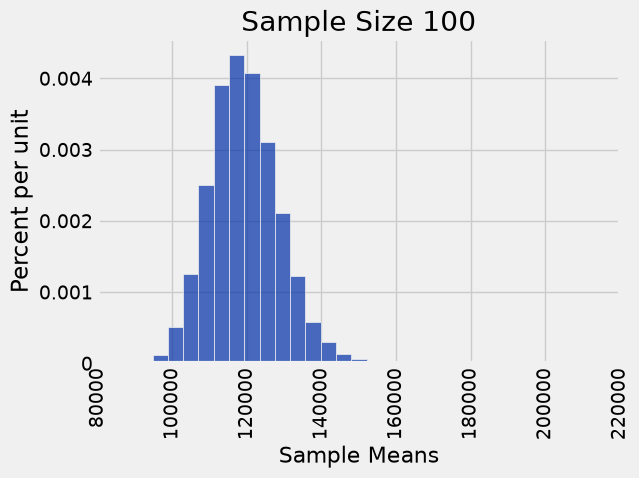

In [15]:
simulate_sample_mean(salaries, 'BASE_SALARY', 100, 10000) 

**Question 2.3.** Simulate the sampling distributions of the mean for samples of 400 salaries and 625 salaries. For each sample size, perform 10,000 repetitions. 

Sample size:  400
Population mean: 119746.117558
Average of sample means:  119748.486135
Population SD: 110592.449798
SD of sample means: 5518.44576547


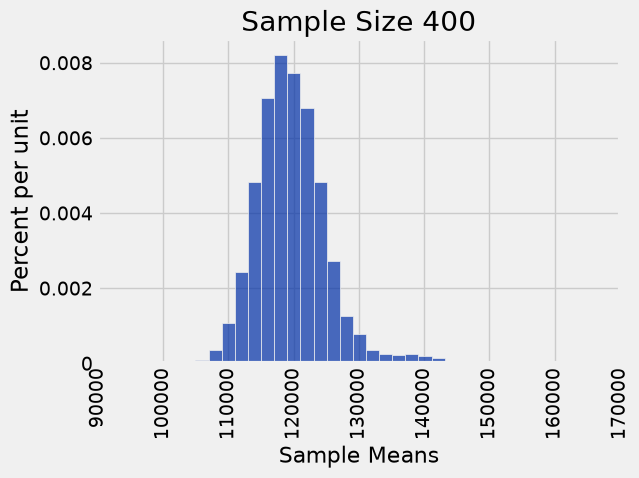



Sample size:  625
Population mean: 119746.117558
Average of sample means:  119785.853127
Population SD: 110592.449798
SD of sample means: 4516.65003725


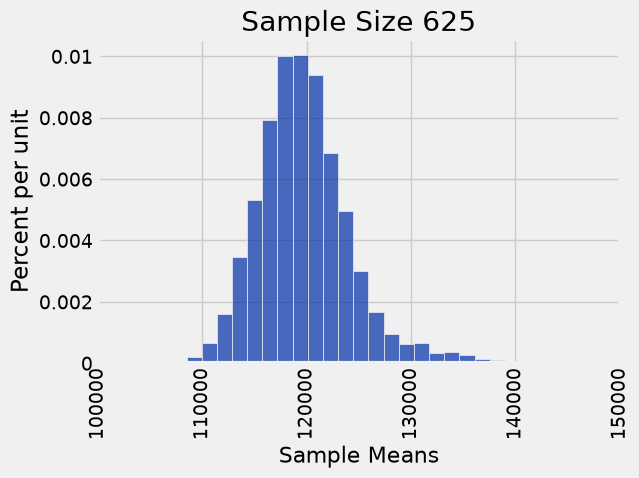

In [16]:
simulate_sample_mean(salaries, 'BASE_SALARY', 400, 10000)
plots.show()
print('\n')
simulate_sample_mean(salaries, 'BASE_SALARY', 625, 10000)
plots.show()

**Question 2.4.** Assign `q2_4` to an array of numbers corresponding to true statement(s) about the plots from 2.3.

1. We see the Law of Averages in action because the distributions of the sample means look like the distribution of the population. 
2. We see the Central Limit Theorem (CLT) in action because the distributions of the sample means are approximately bell-shaped.
3. One of the conditions for CLT is that the population must be normally distributed.
4. One of the conditions for CLT is that we have to draw a small random sample with replacement from the population.
5. One of the conditions for CLT is that we have to draw a large random sample with replacement from the population.
6. Both plots in 2.3 are roughly centered around the mean of a particular sample. 
7. Both plots in 2.3 are roughly centered around the population mean.
8. The distribution of sample means for sample size 625 has more variability than the distribution of sample means for sample size 400.
9. The distribution of sample means for sample size 625 has less variability than the distribution of sample means for sample size 400.

In [17]:
q2_4 = make_array(2, 5, 7, 9)

Below, we'll look at what happens when we take an increasing number of resamples of a fixed sample size. Notice what number in the code changes, and what stays the same. How does the distribution of the resampled means change?

Sample size:  100
Population mean: 119746.117558
Average of sample means:  119447.114513
Population SD: 110592.449798
SD of sample means: 10780.4910194


10780.491019444777

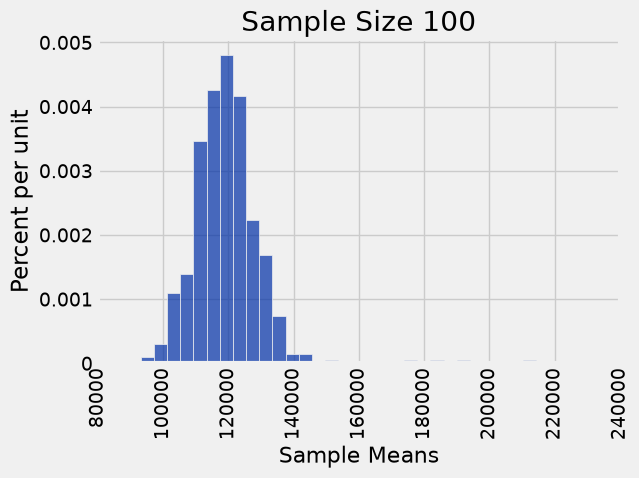

In [18]:
simulate_sample_mean(salaries, 'BASE_SALARY', 100, 500)

Sample size:  100
Population mean: 119746.117558
Average of sample means:  119755.832675
Population SD: 110592.449798
SD of sample means: 11512.1688628


11512.168862849439

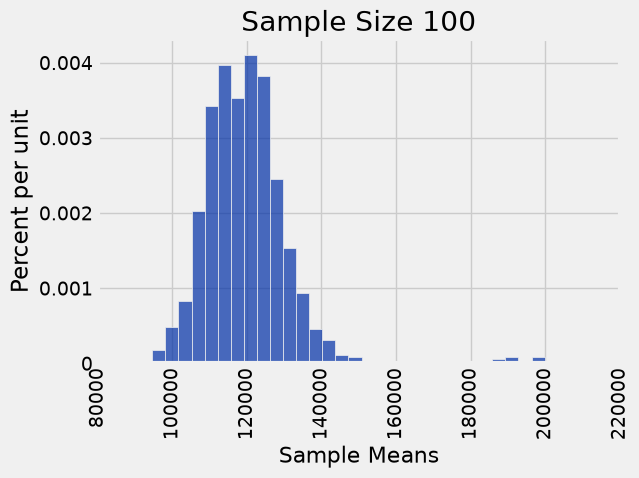

In [19]:
simulate_sample_mean(salaries, 'BASE_SALARY', 100, 1000)

Sample size:  100
Population mean: 119746.117558
Average of sample means:  119426.370644
Population SD: 110592.449798
SD of sample means: 10844.4191534


10844.419153380866

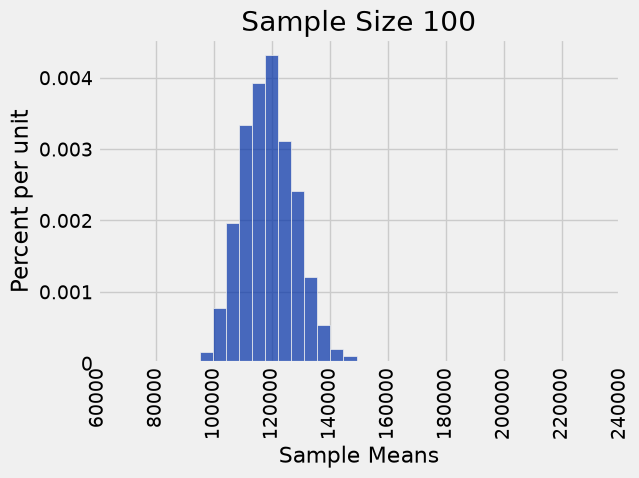

In [20]:
simulate_sample_mean(salaries, 'BASE_SALARY', 100, 5000)

Sample size:  100
Population mean: 119746.117558
Average of sample means:  119710.02579
Population SD: 110592.449798
SD of sample means: 11141.7439958


11141.743995821627

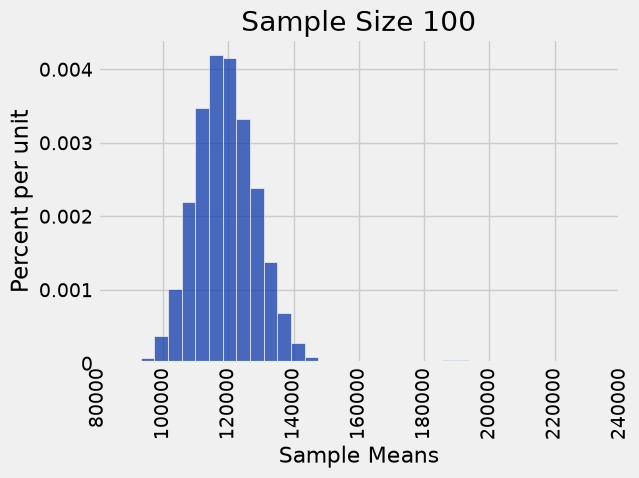

In [21]:
simulate_sample_mean(salaries, 'BASE_SALARY', 100, 10000)

What did you notice about the distributions of sample means in the four histograms above? 

**Question 2.5.** Assign the variable `SD_of_sample_means` to the integer corresponding to your answer to the following question:

When I increase the number of repetitions while keeping the sample size fixed, the SD of the simulated sample means will…

1. Increase
2. Decrease
3. Vary wildly
4. Stay about the same

In [22]:
SD_of_sample_means = 4

**Question 2.6.** Let's think about how the relationships between population SD, sample SD, and SD of sample means change with varying sample size. Which of the following is true? Assign the variable `pop_vs_sample` to an array of integer(s) that correspond to true statement(s).

1. As sample size increases, the sample SD tends to be closer to the population SD. 
2. The sample SD systematically decreases as sample size increases.
3. The sample SD systematically increases as sample size increases.
4. SD of sample means stays the same with increasing sample size.
5. SD of sample means gets smaller with increasing sample size.
6. SD of sample means gets larger with increasing sample size. 

In [23]:
pop_vs_sample = make_array(1, 5)

Run the following three cells multiple times and examine how the sample SD and the SD of sample means change with sample size.

The first histogram is of the sample the second histogram is the distribution of sample means with that particular sample size. You may adjust the bins as necessary.

Sample SD:  58840.4205771
Sample size:  10
Population mean: 119746.117558
Average of sample means:  118611.93714
Population SD: 110592.449798
SD of sample means: 28590.1482831


Text(0.5, 1.0, 'Distribution of sample means for sample size 10')

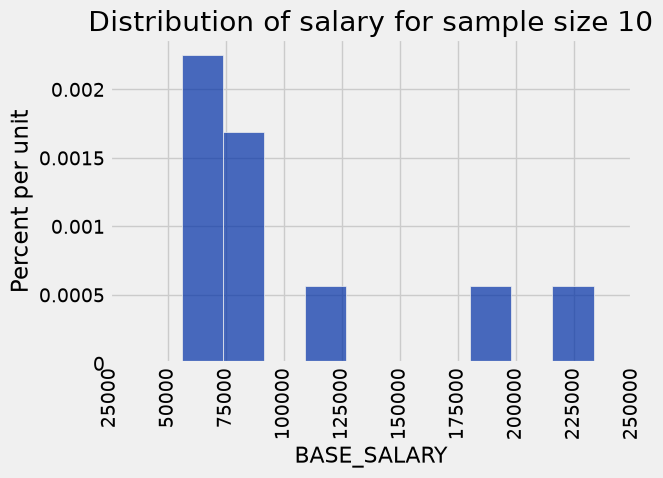

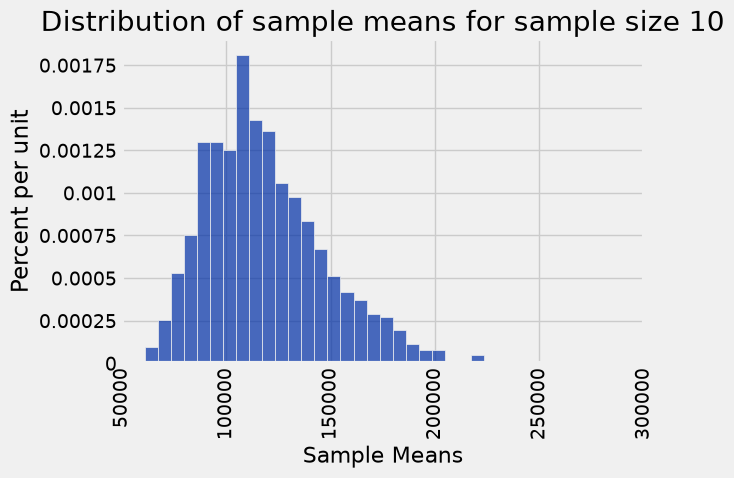

In [24]:
sample_10 = salaries.sample(10)
sample_10.hist('BASE_SALARY')
plots.title('Distribution of salary for sample size 10')
print("Sample SD: ", np.std(sample_10.column('BASE_SALARY')))
simulate_sample_mean(salaries, 'BASE_SALARY', 10, 1000)
plots.title('Distribution of sample means for sample size 10')

Sample SD:  95707.7433575
Sample size:  200
Population mean: 119746.117558
Average of sample means:  119502.162056
Population SD: 110592.449798
SD of sample means: 7578.5573056


Text(0.5, 1.0, 'Distribution of sample means for sample size 200')

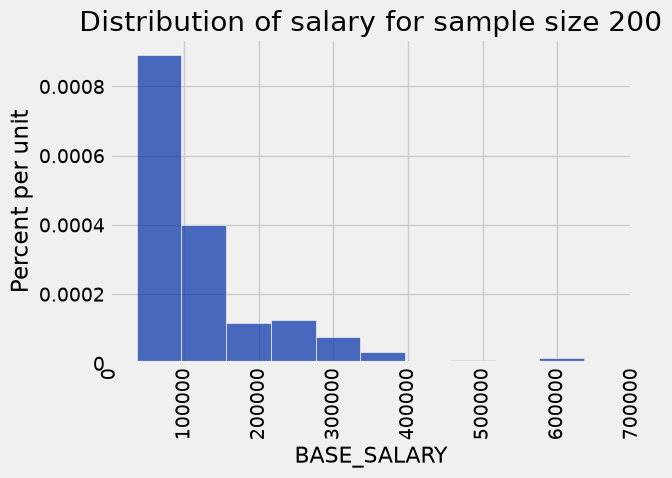

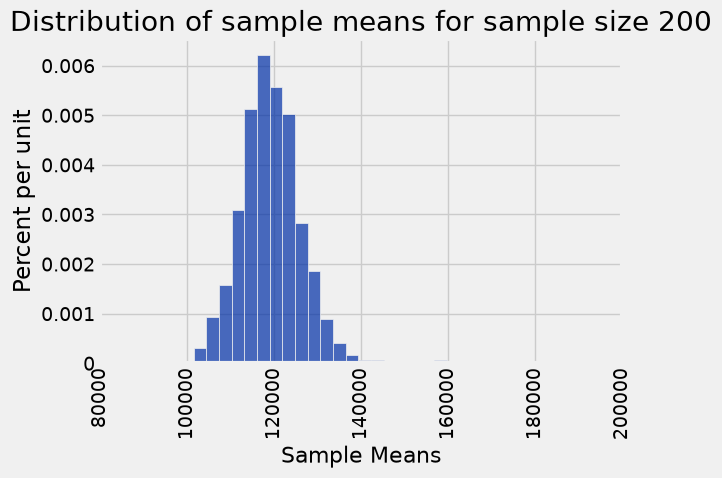

In [25]:
sample_200 = salaries.sample(200)
sample_200.hist('BASE_SALARY')
plots.title('Distribution of salary for sample size 200')
print("Sample SD: ", np.std(sample_200.column('BASE_SALARY')))
simulate_sample_mean(salaries, 'BASE_SALARY', 200, 1000)
plots.title('Distribution of sample means for sample size 200')

Sample SD:  84110.4285956
Sample size:  1000
Population mean: 119746.117558
Average of sample means:  119777.515692
Population SD: 110592.449798
SD of sample means: 3603.36028006


Text(0.5, 1.0, 'Distribution of sample means for sample size 1000')

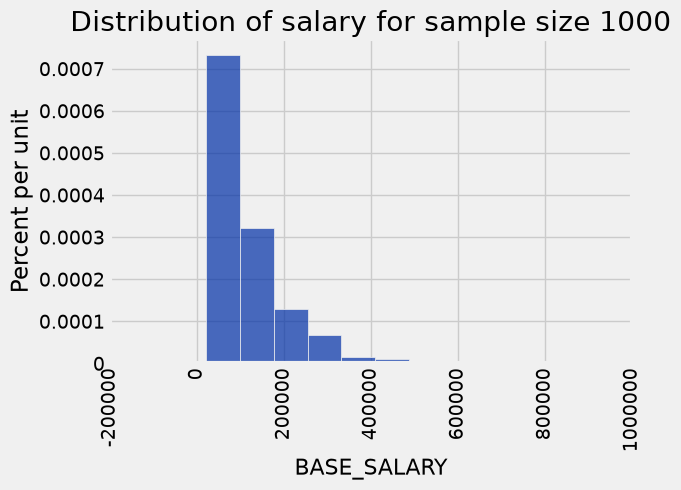

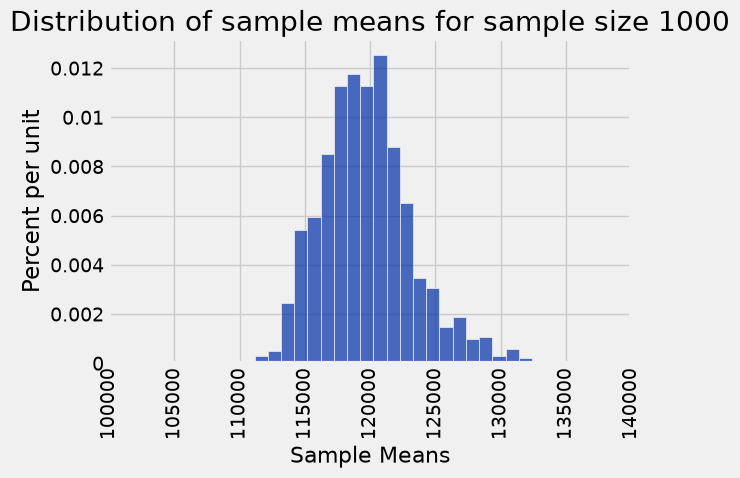

In [26]:
sample_1000 = salaries.sample(1000)
sample_1000.hist('BASE_SALARY')
plots.title('Distribution of salary for sample size 1000')
print("Sample SD: ", np.std(sample_1000.column('BASE_SALARY')))
simulate_sample_mean(salaries, 'BASE_SALARY', 1000, 1000)
plots.title('Distribution of sample means for sample size 1000')

You should notice that the sampling distribution of the mean becomes narrower as the sample size increases. You should also notice that larger samples tend to produce sample distributions that more closely resemble the population distribution.

Let's illustrate these trends. Below, you will see how the sample SD changes as the sample size $N$ increases. The gold line represents the population SD. Because the salary distribution has a few very high values, observations in the upper tail can have a large effect on the sample SD.

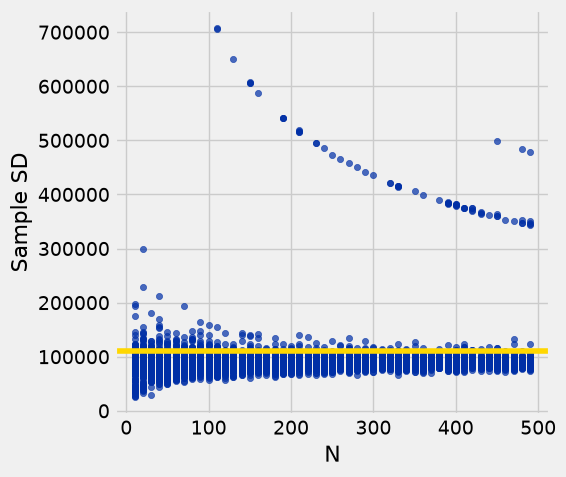

In [27]:
# Don't change this cell, just run it!
pop_sd = np.std(salaries.column('BASE_SALARY'))
sample_sds = make_array()
sample_sizes = make_array()
for i in np.arange(10, 500, 10):
    sample_sds = np.append(sample_sds, [np.std(salaries.sample(i).column('BASE_SALARY')) for d in np.arange(100)])
    sample_sizes = np.append(sample_sizes, np.ones(100) * i)
Table().with_columns("Sample SD", sample_sds, "N", sample_sizes).scatter("N", "Sample SD")
plots.axhline(y=pop_sd, color='gold', linestyle='-')

The next cell shows how the SD of the sampling distribution of the mean changes as the sample size $N$ increases.

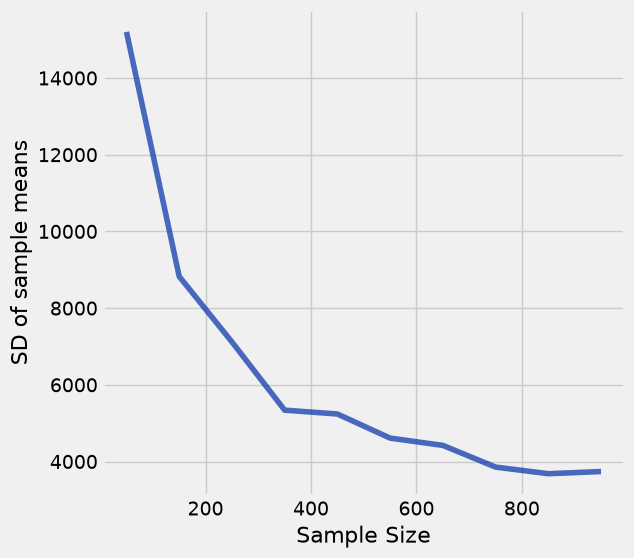

In [28]:
# Don't change this cell, just run it!
def sample_means_sd(sample_size):
    means = make_array()
    for i in np.arange(1000):
        sample = salaries.sample(sample_size).column('BASE_SALARY')
        means = np.append(means, np.mean(sample))
    return np.std(means)

sample_mean_SDs = make_array()
for i in np.arange(50, 1000, 100):
    sample_mean_SDs = np.append(sample_mean_SDs, sample_means_sd(i))
Table().with_columns("SD of sample means", sample_mean_SDs, "Sample Size", np.arange(50, 1000, 100))\
.plot("Sample Size", "SD of sample means")

From these two plots, we can see that the sample SD tends to become closer to the population SD as sample size increases. In contrast, the SD of the sampling distribution of the mean decreases as sample size increases.

**Question 2.7.** How is the SD of the sampling distribution of the mean related to sample size? Assign `q2_7` to the number corresponding to the statement that answers this question.

1. The SD of the sample means is directly proportional to the square root of sample size. 
2. The SD of the sample means is inversely proportional to the square root of sample size.

In [29]:
q2_7 = 2

Throughout this lab, we have taken repeated random samples from a population. Similar ideas apply when we take bootstrap resamples from a single sample. In a bootstrap procedure, we repeatedly sample with replacement from the observed sample, treating it as an approximation to the population.. If your original sample is relatively large, all of your re-samples will also be relatively large, and so the SD of resampled means will be relatively small. 

In order to change the variability of your sample mean, you’d have to change the size of the original sample from which you are taking bootstrapped resamples.

That's it! You've completed Lab 7. 